# 3 — Train on one date, predict on another

A graph is just data: `train` and `embed` never assume the inference graph is the training one.
This notebook trains on **2018-01-01** and embeds **2018-01-02**, whose network is a different
`Data` object with its own edges.

Two inference inputs are shown:

1. **fully observed** — the new date is complete, so it embeds `num_nodes` rows;
2. **partly observed** — half its locations are withheld and supplied as `query_positions`, which
   is what deployment looks like when new locations arrive without features.

Both files are in `notebooks/data/`.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import torch
from scipy.spatial import cKDTree

from nofe import NOFE, build_graph
from nofe.affinity import affinity_kl_loss

# Resolve paths from the repository layout, not the process cwd: VS Code always starts kernels in
# the workspace folder (`jupyter.notebookFileRoot` is ignored since 2024.4), while `_execute.py`
# runs from `notebooks/`. Walk up from the cwd looking for the repo root, so both agree.
REPO = next(
    (
        ancestor
        for ancestor in (Path.cwd(), *Path.cwd().parents)
        if (ancestor / "pyproject.toml").is_file()
    ),
    None,
)
if REPO is None:
    raise RuntimeError(f"run this notebook from inside the nofe checkout, not {Path.cwd()}")
NOTEBOOKS = REPO / "notebooks"
DATA = NOTEBOOKS / "data"

# The example data is not in Git (21 MB per date), so fail with the fetch command rather than the
# opaque `StopIteration`/`FileNotFoundError` the loader would otherwise raise.
if not (DATA / "2018-01-01.nc").exists():
    raise FileNotFoundError(
        f"missing {DATA / '2018-01-01.nc'}\n"
        "The ERA5 inputs are not committed. Fetch them once with:\n"
        f"  mkdir -p {DATA}\n"
        f"  cp /Volumes/T7-storage/ERA5/data/2018-01-0{{1,2}}.nc {DATA}/"
    )

# The notebooks import the ERA5 helpers straight from the example script, so the loader and the
# globe plot have exactly one implementation in the repo. `era5` is imported after `sys.path` is
# extended, which is why the noqa marker below is needed.
sys.path.insert(0, str(REPO / "examples"))
import era5  # noqa: E402


def kl(on, embedding) -> float:
    """Mean KL between a graph's own feature affinities and an embedding of its rows."""
    return float(affinity_kl_loss(on.x, embedding, on.edge_index, on.num_nodes))


def pca_baseline(data, dims: int = 3) -> torch.Tensor:
    """Best linear projection to ``dims`` dimensions: the reference the model has to beat."""
    centred = data.x - data.x.mean(dim=0, keepdim=True)
    _, _, basis = torch.linalg.svd(centred, full_matrices=False)
    return centred @ basis[:dims].T


def knn_agreement(reference: torch.Tensor, candidate: torch.Tensor, k: int = 10) -> float:
    """Mean share of exact k-nearest neighbours two point sets have in common."""
    ref = reference.detach().cpu().numpy()
    cand = candidate.detach().cpu().numpy()
    _, ref_nn = cKDTree(ref).query(ref, k=k + 1)
    _, cand_nn = cKDTree(cand).query(cand, k=k + 1)
    shared = [len(set(a) & set(b)) / k for a, b in zip(ref_nn[:, 1:], cand_nn[:, 1:], strict=True)]
    return float(np.mean(shared))


def close(a: torch.Tensor, b: torch.Tensor, rtol: float = 1e-4) -> bool:
    """Relative agreement in units of the embedding's own scale."""
    return bool((a - b).abs().max() <= rtol * a.abs().max())


print("nofe ready; the faiss fallback warning is expected on macOS arm64")


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


nofe ready; the faiss fallback warning is expected on macOS arm64


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Load both dates at the same resolution

Same `stride` gives identical lat/lon axes — convenient for plotting, and *not* required for the
transfer to work.

In [2]:
STRIDE = 8
train_features, train_latitudes, train_longitudes = era5.load_fields(
    DATA / "2018-01-01.nc", stride=STRIDE
)
test_features, test_latitudes, test_longitudes = era5.load_fields(
    DATA / "2018-01-02.nc", stride=STRIDE
)
assert np.array_equal(train_latitudes, test_latitudes)
assert np.array_equal(train_longitudes, test_longitudes)

positions_train = era5.unit_sphere(train_latitudes, train_longitudes)
positions_test = era5.unit_sphere(test_latitudes, test_longitudes)
flat_train = train_features.reshape(-1, train_features.shape[2])
flat_test = test_features.reshape(-1, test_features.shape[2])
print(
    "training date nodes:",
    positions_train.shape[0],
    "| new date nodes:",
    positions_test.shape[0],
)


training date nodes: 16020 | new date nodes: 16020


## Train on the first date

Nothing here knows a second date exists.

In [3]:
CONFIG = {
    "width": 8,
    "ker_width": 32,
    "epochs": 200,
    "seed": 0,
    "early_stopping": False,
    "verbose": True,
    "log_every": 50,
}

train_graph = build_graph(positions_train, flat_train, neighbor="knn", k=era5.K)
model = NOFE(dim=3, config=CONFIG)
history = model.train(train_graph)
print(
    f"loss {history[0]['train_loss']:.5f} -> {history[-1]['train_loss']:.6f} "
    f"| mean KL {model.loss(train_graph):.6f}"
)


/Users/laueb4818/github/NOFE-pkg/src/nofe/graphs.py:196: RuntimeWarning: faiss-cpu is installed but the process maps two OpenMP runtimes, so its parallel search would abort; falling back to scipy cKDTree, which is much slower for kNN search on large point sets. Install nofe's faiss-cpu dependency to silence this warning.
  neighbor, query = _pairs(points, src_ids, dst_ids, radius=radius, k=k)


epoch   50/200  train 0.024049  val 0.023846


epoch  100/200  train 0.015816  val 0.015392


epoch  150/200  train 0.014997  val 0.014666


epoch  200/200  train 0.014531  val 0.014351
loss 0.12680 -> 0.014531 | mean KL 0.014520


## Predict on the second date, fully observed

The new graph carries its own `x`, `pos` and edges. The only compatibility requirement is the
widths: 11 input features and `2P + 1 = 7` edge channels, which `build_graph` reproduces for any
point set of the same dimension.

In [4]:
test_graph = build_graph(positions_test, flat_test, neighbor="knn", k=era5.K)
built = model.model.config
print(
    "feature width matches:",
    test_graph.x.shape[1] == built["in_channels"],
    "| edge width matches:",
    test_graph.edge_attr.shape[1] == built["edge_channels"],
)

embedding_transfer = model.embed(test_graph)
assert embedding_transfer.shape == (test_graph.num_nodes, 3)
print("embedding on 2018-01-02:", tuple(embedding_transfer.shape))

# The new date is fully observed, so its KL is a real score, not a placeholder.
print(f"mean KL on the new date : {model.loss(test_graph):.6f}")
print(f"PCA-3 KL on the new date: {kl(test_graph, pca_baseline(test_graph, dims=3)):.6f}")


feature width matches: True | edge width matches: True
embedding on 2018-01-02: (16020, 3)
mean KL on the new date : 0.016603
PCA-3 KL on the new date: 0.054486


## Compare how each date maps into the shared embedding

The embedding is a *function* of local feature neighbourhoods, so two dates land in the same space:
similar weather regimes get similar colours even though the raw fields differ. The next cell
quantifies that instead of eyeballing it.

In [5]:
train_embedding = model.embed(train_graph)
print(f"KL on the training date: {kl(train_graph, train_embedding):.6f}")
print(f"KL on the new date     : {kl(test_graph, embedding_transfer):.6f}")
assert kl(test_graph, embedding_transfer) < kl(test_graph, pca_baseline(test_graph, dims=3))
print("transfer beats linear PCA on the unseen date: True")


KL on the training date: 0.014520
KL on the new date     : 0.016603


transfer beats linear PCA on the unseen date: True


## Partly observed second date

Withhold half the locations of 2018-01-02 and hand them to `build_graph` as `query_positions`.
Their features become the `fill` substitute, they receive messages without sending any, and their
truth — when supplied — goes to `y` for scoring only.

`test_blind` is the honest deployment case: no truth exists for the new locations.

In [6]:
rng = np.random.default_rng(0)
observed_test = rng.random(positions_test.shape[0]) < 0.5
print(f"observed {observed_test.sum()} of {observed_test.size} locations on the second date")

test_merged = build_graph(
    positions_test[observed_test],
    flat_test[observed_test],
    query_positions=positions_test[~observed_test],
    query_features=flat_test[~observed_test],
    neighbor="knn",
    k=era5.K,
)
test_blind = build_graph(
    positions_test[observed_test],
    flat_test[observed_test],
    query_positions=positions_test[~observed_test],
    neighbor="knn",
    k=era5.K,
)
print(
    "merged and blind agree on the graph:",
    torch.equal(test_merged.x, test_blind.x)
    and torch.equal(test_merged.edge_index, test_blind.edge_index),
)

predicted = model.embed(test_blind)
print("prediction for all locations:", tuple(predicted.shape))
print(f"mean KL where truth exists   : {model.loss(test_merged):.6f}")


observed 7986 of 16020 locations on the second date


merged and blind agree on the graph: True
prediction for all locations: (16020, 3)
mean KL where truth exists   : 0.076736


## Two ways to predict the partly observed date

`output_mask` picks which rows come back. Restricting it to the observed rows reproduces a plain
observed-only prediction; leaving it wide returns the withheld locations too. The graph, its edges
and every `x` row are identical in both calls.

In [7]:
# `test_blind` reorders nodes (observed first, then added), and its own `input_mask` marks the
# observed prefix. A mask in grid order would not line up with the graph's rows.
observed_rows = test_blind.clone()
observed_rows.output_mask = test_blind.input_mask
observed_prediction = model.embed(observed_rows)
num_observed_test = int(observed_test.sum())

print("all locations :", tuple(predicted.shape))
print("observed only :", tuple(observed_prediction.shape))
max_diff = (observed_prediction - predicted[:num_observed_test]).abs().max()
print(f"max diff vs the matching prefix: {max_diff:.2e}")
assert close(observed_prediction, predicted[:num_observed_test])
print("observed-only rows are the matching prefix of the full prediction: True")


all locations : (16020, 3)
observed only : (7986, 3)
max diff vs the matching prefix: 5.72e-06
observed-only rows are the matching prefix of the full prediction: True


## Visualise the transfer

Top to bottom: the training date, the new date fully observed, and the new date with half its
locations withheld and predicted.

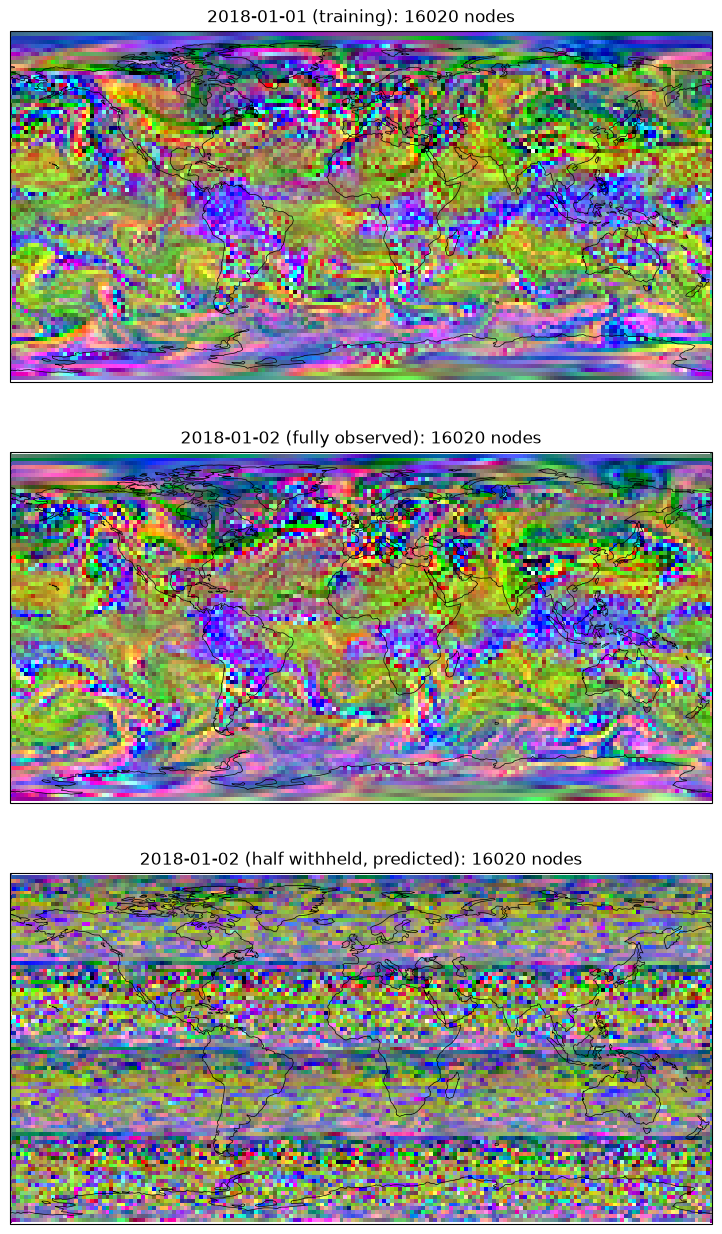

In [8]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

grid_index_test = np.empty(test_merged.num_nodes, dtype=np.int64)
grid_index_test[observed_test] = np.arange(num_observed_test)
grid_index_test[~observed_test] = np.arange(num_observed_test, test_merged.num_nodes)

predicted_grid = np.full((grid_index_test.size, 3), np.nan, dtype=np.float32)
predicted_grid[grid_index_test] = predicted.numpy()

panels = [
    ("2018-01-01 (training)", train_embedding.numpy()),
    ("2018-01-02 (fully observed)", embedding_transfer.numpy()),
    ("2018-01-02 (half withheld, predicted)", predicted_grid),
]

# All three panels share one colour scale, computed from the training embedding: without it each
# panel would rescale independently and the same weather regime would get a different colour.
scale = era5.colour_scale(panels[0][1], era5.PERCENTILE)

figure, axes = plt.subplots(
    3, 1, figsize=(12.0, 15.5), subplot_kw={"projection": ccrs.PlateCarree()}
)
for axis, (title, values) in zip(axes, panels, strict=True):
    axis.set_global()
    era5.draw_globe(axis, test_latitudes, test_longitudes, values, scale=scale)
    axis.coastlines(linewidth=0.5)
    axis.set_title(f"{title}: {values.shape[0]} nodes")
plt.show()


## Takeaways

|Fact|Why it matters|
|---|---|
|`train` and `embed` take different `Data`|A graph is data, not state; transfer needs no re-fitting|
|Only the widths must match|`in_channels` = features, `edge_channels` = `2P + 1`|
|`blind` graphs are embed-only|`train`/`loss` refuse scored rows holding substitutes with no `y`|
|`output_mask` chooses the rows|Same graph and inputs; only the returned subset changes|

To adapt to the new date rather than just score it, build a fresh `NOFE` and call `train` on the new
graph; nothing about the objects changes.